#**Proyecto Final Estadística 2024-2**

Nevis Saray Perez Herrera

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pandas as pd
import scipy.stats as sc
import scipy.stats as stats

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Ejercicio 12.5
Los siguientes datos representan el efecto del tiempo en la pérdida
de hidrógeno en muestras de acero almacenadas a una temperatura de
20°C

In [ ]:
t = np.array([1,2,6,17,30])
Hidrogeno_perdido = np.array([8.1,7.8,6.5,5.5,4.4])

a) *Dibuje un diagrama de dispersión para los datos anteriores*

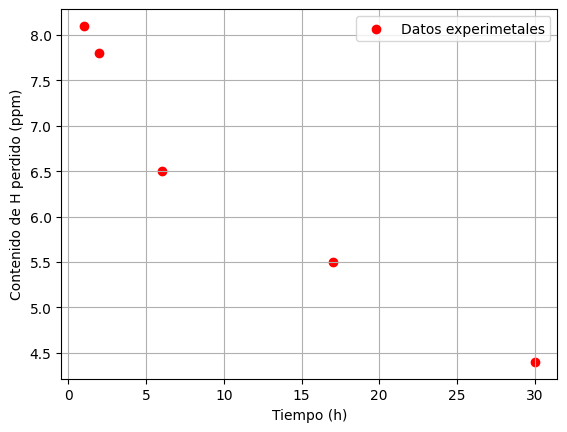

In [ ]:
plt.scatter(t,Hidrogeno_perdido, color="r", label="Datos experimetales")
plt.xlabel("Tiempo (h)")
plt.ylabel("Contenido de H perdido (ppm)")
plt.legend()
plt.grid()
plt.show()

Podemos observar en el diagrama de dispersion que efectivamente los datos tienen un comportamiento lineal, a mayor tiempo menor contenido de hidrógeno, por lo tanto, podemos realizar una regresion lineal.

b) *Determine la ecuación de la recta de regresión lineal y dibújela
en el diagrama*

Obtener la ecuación de la recta con las formulas:

la ecuación de la recta es $y=mx+b$ tenemos que calcular m y b entonces usamos las formulas:

$$m = \frac{n\sum(x_iy_i)-\sum{x_i}\sum{y_i}}{n\sum{x_i^2}-(\sum{x_i})^2}$$  

$$b = \frac{\sum{y_i}-m\sum{x_i}}{n}$$

Para poder trabajar con esta formula armamos la tabla:

\begin{array}{|c|c|} \hline
x(tiempo) & y(H perdido) & xy & x^2 \\ \hline
1 & 8.1 & 8.1 & 1 \\ \hline
2 & 7.8 & 15.6 & 4 \\\hline
6 & 6.5 & 39 & 36 \\ \hline
17 & 5.5 & 93.5 & 289 \\ \hline
30 & 4.4 & 132 & 900 \\\hline
suma: 56 & 32.3 & 288.2 & 1230 \\ \hline
\end{array}

sustituyendo en las formulas obtenemos que: $m = -0.1221$ y $b = 7.8275$

por lo tanto la ecuación de la recta viene siendo

$y = -0.1221x+7.8275$

Lo cual tiene sentido con los datos que tenemos ya que como la pendiente es negativa esta indicando que por cada hora que pasa la cantidad de hidrogeno disminuye en 0.1221 ppm

hagamoslo con la libreria Scipy en phyton:

La ecuacion de la recta es H=-0.1220t + 7.8267


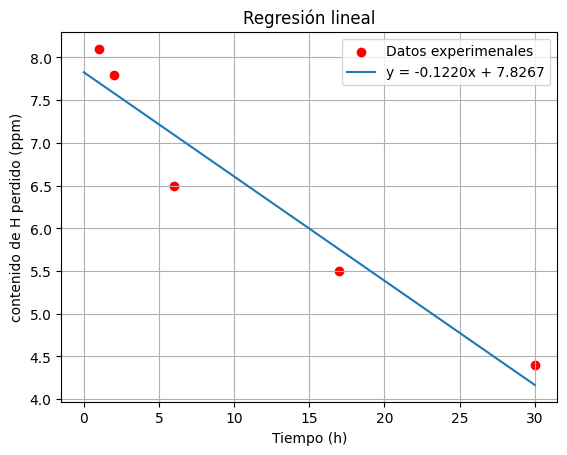

In [ ]:
#Ecuación de la recta
slope, intercepto, r_valor, p_valor, std_err = linregress(t, Hidrogeno_perdido)
print(f"La ecuacion de la recta es H={slope:.4f}t + {intercepto:.4f}")

t_regresion = np.linspace(0,30,100)
H_regresion = -0.1220*t_regresion + 7.8267

#grafica
plt.scatter(t,Hidrogeno_perdido, color= "r", label="Datos experimenales")
plt.plot(t_regresion, H_regresion, label=f"y = {slope:.4f}x + {intercepto:.4f}")
plt.xlabel("Tiempo (h)")
plt.ylabel("contenido de H perdido (ppm)")
plt.title("Regresión lineal")
plt.legend()
plt.grid()
plt.show()

En la gráfica podemos observar la recta del ajuste lineal que le hemos realizado a los datos.

c) Determine el intervalo de confianza del 95% para el contenido de hidrógeno perdido en 20 horas

estimemos la perdida de hidrogeno cuando $t=20h$ y calcular su intervalo de confianza

entonces tenemos que el intervalo de confianza con la formula:

$$IC=H_{pred}\pm t_{\alpha/2,n-2}* s_{res}*\sqrt{1+\frac{1}{n}+\frac{(t_{pred}-\bar{t})^2}{\sum{(t_i-\bar{t})^2}}}$$


Para esto necesitamos la ecuación de la recta encontrada en el punto b) la cual sera evaluada en el valor de t = 20 en esta ecuación para hallar: $H_{pred}$ queda claro que $t_{pred}$ es 20

seguido a esto calculamos los residuos de la regresión donde H son los valores de H observado (el que nos dan en el ejercicio) y $H_{pred}$ que resultan de evaluar los valores de t en la ecuación de la recta  entonces los residuis se calculan con la siguiente formula:  $$s_{res} = \sqrt{\frac{\sum_{i}{(H_i-H_{predi})^2}}{n-2}}$$ y ya después evaluamos la raiz que se puede observar en la ecuación $IC$ teniendo en cuenta que $n$ es la cantidad de datos que tenemos:




In [ ]:
n = len(t)
media = np.mean(t)
#calculemos H predecido:
t_horas = 20
H_pre = slope*t_horas + intercepto
residuos = slope*t + intercepto
s_res = np.sqrt(np.sum((Hidrogeno_perdido - residuos) ** 2) / (n - 2))

#Calculo la raiz que se puede observar en la ecuación:
raiz = np.sqrt(1+(1/n)+ ((20 - media)**2)/(np.sum((t- media)**2)))
valor_t_student = 3.182

IC_menor = H_pre - valor_t_student*s_res*raiz
IC_mayor = H_pre + valor_t_student*s_res*raiz

print(f"El intervalo de confianza de 95% es ({round(IC_menor,3)} ,{round(IC_mayor,3)})")

El intervalo de confianza de 95% es (3.646 ,7.126)


Entonces concluimos que el intervalo de confianza del $95\%$ es de $(3.646,7.126)$  lo que podemos interpretar como, que con $95\%$ de confianza el contenido de hidrogeno perdido en 20 horas estara entre $3.646ppm$ y $7.126ppm$


d)Determine el coeficiente de correlación lineal y pruebe la hipótesis p = 0 con a = 0.10.

este coeficiente mide que tan bien se ajustan los datos a la linea de regresión puesto a que nos dice que el grado de relación entre 2 variables entonces sea r el coeficiente:

$$r=\frac{\sum{t_iH_i-n\bar{t}\bar{H}}}{\sqrt{(\sum{t_i^2-nt^2})(\sum{H_i^2-nH^2})}}$$
entonces:

si $r=1$ hay una correlación perfecta positiva

si $r=-1$ correlación perfecta negativa

Cuando calculemos el coeficiente de correlación podemos proceder a la prueba de hipotesis para esto calculamos el estadistico de prueba debido a que en el ejercicio se indica que p=0 entonces podemos usar la siguiente formula (normalmente se llama t pero le llamaremos t_estadistico para no confundirlo con la variable del tiempo)

$$t_{estadistico} = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}}$$

y debido a que el tamaño de la muestra es pequeño usamos la distribución t-student, entonces como ajutamos una recta de regresión lineal entonces estimamos $2$ parametros y cada parametro resta una cantidad de información independiente en los datos por lo que tenemos $n-2$ grados de libertad
y con $\alpha=0.05$ ya que queremos saber si existe algún tipo de correlación.

Entonces al hacer los calculos llegamos a que se rechaza $H_0$ por lo que existe una correlación siginificativa entre el tiempo y la perdida de hidrogeno, es decir existe un alto grado de relación.


In [ ]:
r = r_valor # coeficiente de correlacion

#Ahora veamos la prueba de hipotesis:
t_estadistico = (r*np.sqrt(n-2))/(np.sqrt(1-(r**2))) #estadisico de prueba
t_student = 2.353 # Valor crítico para prueba con α = 0.10

if abs(t_estadistico) > t_student:
  print(abs(t_estadistico)>t_student,"se rechaza H_0")
else:
  print(abs(t_estadistico)<t_student,"se acepta H_0")

print(f"""El coeficiente de correlacion es {round(r,3)},
 El valor estadistico de prueba es {round(t_estadistico,3)},
 el valor critico para prueba con α = 0.10  es {round(t_student,3)}""")

True se rechaza H_0
El coeficiente de correlacion es -0.964,
 El valor estadistico de prueba es -6.314,
 el valor critico para prueba con α = 0.10  es 2.353


#$Proyecto$

Para abordar las preguntas a resolver trabajaremos en la base de datos Real estate price prediction, la cual contiene caracteristicas de una casa y su precio. Analizaremos la relacion entre el precio de la casa con la latitud y la longitud (ubicación).

Esta base de datos la hemos encotrado por internet en una pagina que sube bases de datos de todo tipo en la cual después de revisar varios datos llegamos a la conclusión que esta era la mejor.(https://www.kaggle.com/datasets/quantbruce/real-estate-price-prediction/data)

Buscaremos determinar con un intervalo de confianza del $95\%$ el precio de la casa para una latitud de $25$ y el precio de la casa para una longitud de $122$ aparte de esto buscamos determinar el coeficiente de correlación lineal y probar la hipotesis $H_0$ con $p=0$ y $\alpha = 0.10$, claramente tsmbién analizaremos descriptivamente las variables con las cuales trabajaremos.




In [ ]:
archivo = "/content/drive/MyDrive/Métodos computacionales/Proyecto estadistica/ProbY estad/Real estate.xlsx"
df = pd.read_excel(archivo)

#Excluyo las dos primeras columnas porque son irrelevantes
df = df.iloc[:, 2:]
columnas = df.columns
df

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
409,13.7,4082.01500,0,24.94155,121.50381,15.4
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


##**Analisis descriptivo**

In [ ]:
#Medidas de Tendencia Central
mu_precio , mu_latitud, mu_longitud = df["Y house price of unit area"].mean() , df["X5 latitude"].mean(), df["X6 longitude"].mean()
median_precio , median_latitud, median_longitud = df["Y house price of unit area"].median() , df["X5 latitude"].median(), df["X6 longitude"].median()
moda_precio , moda_latitud, moda_longitud = df["Y house price of unit area"].mode() , df["X5 latitude"].mode(), df["X6 longitude"].mode()

#Medidas de Variabilidad o Dispersion
sigma_precio , sigma_latitud, sigma_longitud = df["Y house price of unit area"].std() , df["X5 latitude"].std(), df["X6 longitude"].std()
var_precio , var_latitud, var_longitud = df["Y house price of unit area"].var() , df["X5 latitude"].var(), df["X6 longitude"].var()

In [ ]:
print(f"""El precio de las casas por unidad de area tiene media = {round(mu_precio,3)} , mediana = {round(median_precio,3)}, desviacion estandar = {round(sigma_precio,3)} y  varianza = {round(var_precio,3)}
La latitud tiene media = {round(mu_latitud,3)} , mediana = {round(median_latitud,3)},desviacion estandar = {round(sigma_latitud,4)} y  varianza = {round(var_latitud,4)}
La longitud tiene media = {round(mu_longitud,3)} , mediana = {round(median_longitud,3)}, desviacion estandar = {round(sigma_longitud,3)} y  varianza = {round(var_longitud,4)}

""")

El precio de las casas por unidad de area tiene media = 37.98 , mediana = 38.45, desviacion estandar = 13.606 y  varianza = 185.137
La latitud tiene media = 24.969 , mediana = 24.971,desviacion estandar = 0.0124 y  varianza = 0.0002
La longitud tiene media = 121.533 , mediana = 121.539, desviacion estandar = 0.015 y  varianza = 0.0002




La longitud, latitud y el precio son variables aleatoras continuas que pueden ser modeladas bajo una distribucion normal


<ipython-input-14-53de6f3151d6>:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
<ipython-input-14-53de6f3151d6>:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()
<ipython-input-14-53de6f3151d6>:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


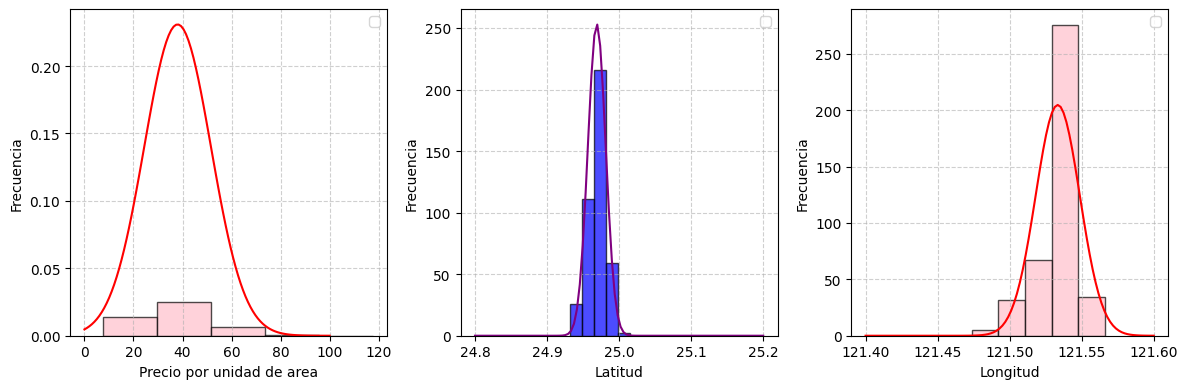

In [ ]:
print("La longitud, latitud y el precio son variables aleatoras continuas que pueden ser modeladas bajo una distribucion normal")
def normal(media, sigma, x):
  y = (1 / sigma * (2*np.pi)**1/2) * np.exp(-((x - media)**2) / (2 * sigma**2))
  return y

t1 = np.linspace(0,100, 100)
t2 = np.linspace(24.8,25.2, 100)
t3 = np.linspace(121.4,121.6, 100)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].hist(df["Y house price of unit area"] , bins=5, color="pink", edgecolor="black", alpha=0.7 , density = True)
axes[0].plot(t1, normal(mu_precio,sigma_precio,t1), color="red")
axes[0].set_xlabel("Precio por unidad de area")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].hist( df["X5 latitude"] , bins=5, color="blue", edgecolor="black", alpha=0.7 )
axes[1].plot(t2, normal(mu_latitud,sigma_latitud, t2), color="purple")
axes[1].set_xlabel("Latitud")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

axes[2].hist(df["X6 longitude"] , bins=5, color="pink", edgecolor="black", alpha=0.7 )
axes[2].plot(t3, normal(mu_longitud,sigma_longitud,t3), color="red")
axes[2].set_xlabel("Longitud")
axes[2].set_ylabel("Frecuencia")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

La longitud, latitud y el precio son variables aleatoras continuas que pueden ser modeladas bajo una distribucioón normal esto lo podemos evidenciar en las gráficas que son en forma de campana aparte podemos observar que:

El precio de las casas por unidad de area tiene $media=37.98$, $mediana = 38.45$

La latitud tiene $media = 24.969$ , $mediana = 24.971$

La longitud tiene $media = 121.533$ , $mediana = 121.539$

Estos resultados tienen también comprueban que los datos siguen una disribución normal debido a que las medidas de tendencia central son iguales (o parecidas debido a que estamos trabajando con datos reales que tienen incertidumbre) entonces la distribución que siguen los datos es normal

#**procedimiento y cálculos**

Realizaremos los calculos (en python) con el fin de dar resolución a las preguntas pincipales.

Graficamos los diagramas de dispersión para poder visualizar que tipo de relación tienen las variables:

In [ ]:
latitud = df.iloc[:,3]
longitud = df.iloc[:,4]
precio = df.iloc[:,5]

<ipython-input-20-b6d73bb61394>:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
<ipython-input-20-b6d73bb61394>:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


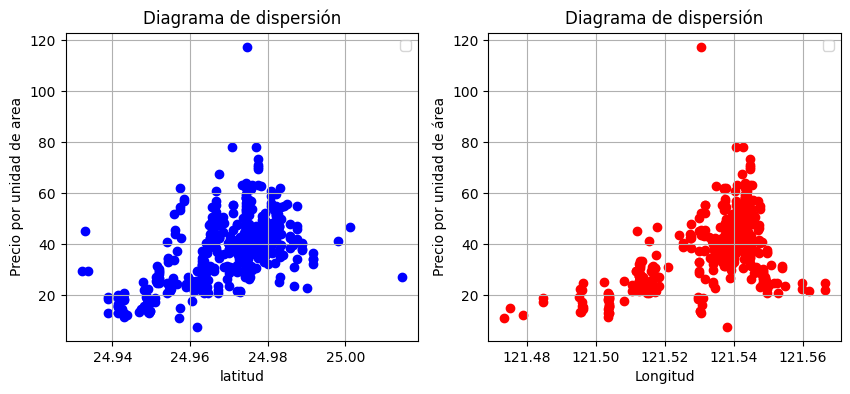

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(latitud,precio, color="b")
plt.title("Diagrama de dispersión")
plt.xlabel("latitud")
plt.ylabel("Precio por unidad de area")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.scatter(longitud,precio, color="r")
plt.title("Diagrama de dispersión")
plt.xlabel("Longitud")
plt.ylabel("Precio por unidad de área")
plt.legend()
plt.grid()

plt.show()

En los diagramas de dispersión podemos visualizar una tendencia lineal en los datos por lo que procedemos a hacerle un ajuste lineal con el fin de calcular la recta de regresión:

Sean "a" la latitud y "b" la longitud

In [ ]:
#Para la latitud
pendiente_lat, intercepto_lat, r_valor_lat, p_valor_lat, std_err = linregress(latitud, precio)
print(f"El precio por unidad de Area en funcion de la latitud:   P(latitud) ={pendiente_lat:.4f}a {intercepto_lat:.4f}")

latitud_regresion = np.linspace(24.92,25.02,1000)
preciolat_regresion = 598.9683*latitud_regresion - 14917.6781

#Para la longitud
pendiente_lon, intercepto_lon, r_valor_lon, p_valor_lon, std_err = linregress(longitud, precio)
print(f"El precio por unidad de area en funcion de la longitud: P(longitud)={pendiente_lon:.4f}b {intercepto_lon:.4f}")

longitud_regresion = np.linspace(121.47353,121.56627,1000)
preciolon_regresion = 463.9347*longitud_regresion - 56345.5686


El precio por unidad de Area en funcion de la latitud:   P(latitud) =598.9683a -14917.6781
El precio por unidad de area en funcion de la longitud: P(longitud)=463.9347b -56345.5686


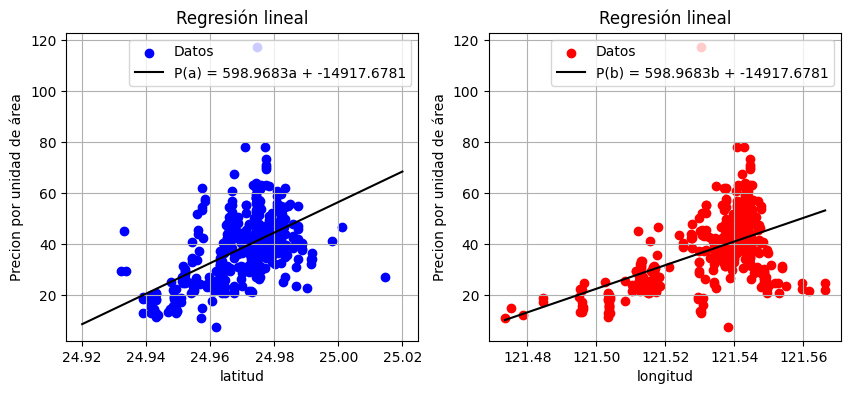

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(latitud,precio, color= "b", label="Datos")
plt.plot(latitud_regresion, preciolat_regresion,color="black",label=f"P(a) = {pendiente_lat:.4f}a + {intercepto_lat:.4f}")
plt.xlabel("latitud")
plt.ylabel("Precion por unidad de área")
plt.title("Regresión lineal")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.scatter(longitud,precio, color= "r", label="Datos")
plt.plot(longitud_regresion, preciolon_regresion,color="black", label=f"P(b) = {pendiente_lat:.4f}b + {intercepto_lat:.4f}")
plt.xlabel("longitud")
plt.ylabel("Precion por unidad de área")
plt.title("Regresión lineal")
plt.legend()
plt.grid()

plt.show()

ahora vamos a proceder a determinar el intervalo de confianza del $95\%$, determinar el coeficiente de correlacion $r$ y probar la hipotesis $H_0$

Comencemos con la variable precio y latitud:

El intervalo de confianza del 95% para el precio de una casa con una latitud de 25:

entonces tenemos el intervalo de confianza con la formula:

$$IC=y_{pred}\pm t_{\alpha/2,m-2}* s_{res}*\sqrt{1+\frac{1}{m}+\frac{(a_{pred}-\bar{a})^2}{\sum{(a_i-\bar{a})^2}}}$$


In [ ]:
m = len(latitud)
print(m)
media_latitud = np.mean(latitud)
#calculemos y predecido:
latitud_pred = 25
y1_pre = pendiente_lat*latitud_pred + intercepto_lat
print(y1_pre)


residuos_lat = pendiente_lat*latitud + intercepto_lat
s_res_lat = np.sqrt(np.sum((precio - residuos_lat) ** 2) / (m - 2))
print(s_res_lat)

#Calculo la raiz que se puede observar en la ecuación:
raiz_lat = np.sqrt(1+(1/m)+ ((latitud_pred - media_latitud)**2)/(np.sum((latitud- media_latitud)**2)))
print(raiz_lat)

#Debido a que la muestra es grande podemos usar un valor de la distribución normal que para el 95% de confianza es Z_0.025≈1.96.
valor_normal_lat= 1.96
print(valor_normal_lat)

#Calculo el intervalo de confianza:

IC_menor_latitud = y1_pre - valor_normal_lat*s_res_lat*raiz_lat
IC_mayor_latitud = y1_pre + valor_normal_lat*s_res_lat*raiz_lat

print("El intervalo de confianza del 95% es (",IC_menor_latitud,",",IC_mayor_latitud,")")

414
56.53019906254485
11.410415756879463
1.0087093114543872
1.96
El intervalo de confianza del 95% es ( 33.97100552434571 , 79.08939260074399 )


Aclaramos que si se usaba t-student obteniamos casi el mismo valor ya que para nuestra cantidad de datos en este intevalo de confianza t-student es 1.965 y con la distribución normal encontramos que es de 1.960 por lo que vemos que la diferencia es minima sin embargo use la normal debido a que se recomienda usarla cuando tenemos que la cantidad de nuestros datos es mayor que 30.

finalmente buscamos el coeficiente de correlación lineal y se prueba la hipótesis p = 0 con a = 0.10.

Entonces el coeficiente de correlación ya lo conocemos:

In [ ]:
r_lat = r_valor_lat
print(r_lat)

#Ahora veamos la prueba de hipotesis:
#estadisico de prueba
t_estadistico_lat = (r_lat*np.sqrt(m-2))/(np.sqrt(1-(r_lat**2)))

# Valor crítico para prueba con α = 0.10 usamos la normal
z_lat = 1.645

if abs(t_estadistico_lat) > z_lat:
  print(abs(t_estadistico_lat)>z_lat,"se rechaza H_0")

else:
  print(abs(t_estadistico_lat)<z_lat,"se acepta H_0")

(r_lat, t_estadistico_lat,z_lat)

0.5463066525036047
True se rechaza H_0


(0.5463066525036047, 13.23902734780033, 1.645)

De forma analoga hagamosla con la variable longitud:

In [ ]:
q = len(longitud) #tamaño de la muestra
print(q)
media_longitud = np.mean(longitud) #el promedio de los datos de la variable longitud
#calculemos y_predecido:
longitud_pred = 122
y2_pre = pendiente_lon*longitud_pred + intercepto_lon
print(y2_pre)


residuos_lon = pendiente_lon*longitud+ intercepto_lon
s_res_lon = np.sqrt(np.sum((precio - residuos_lon) ** 2) / (q - 2))
print(s_res_lon)

#Calculo la raiz que se puede observar en la ecuación:
raiz_lon = np.sqrt(1+(1/q)+ ((longitud_pred - media_longitud)**2)/(np.sum((longitud- media_longitud)**2)))
print(raiz_lon)

#Debido a que la muestra es grande podemos usar un valor de la distribución normal que para el 95% de confianza es Z_0.025≈1.96.
valor_normal_lat= 1.96 #dejo la misma varibale debido a que la el valor es el mismo
print(valor_normal_lat)

#Calculo el intervalo de confianza:

IC_menor_longitud = y2_pre - valor_normal_lat*s_res_lon*raiz_lon
IC_mayor_longitud = y2_pre + valor_normal_lat*s_res_lon*raiz_lon

print("El intervalo de confianza del 95% es (",IC_menor_longitud,",",IC_mayor_longitud,")")

414
254.47019795836968
11.60892407893822
1.8002505679129195
1.96
El intervalo de confianza del 95% es ( 213.50821251307536 , 295.432183403664 )


In [ ]:
r_lon = r_valor_lon
print(r_lon)

#Ahora veamos la prueba de hipotesis:
#estadisico de prueba
t_estadistico_lon = (r_lon*np.sqrt(q-2))/(np.sqrt(1-(r_lon**2)))

# Valor crítico para prueba con α = 0.10 usamos la normal
z_lon = 1.645

if abs(t_estadistico_lon) > z_lon:
  print(abs(t_estadistico_lon)>z_lon,"se rechaza H_0")

else:
  print(abs(t_estadistico_lon)<z_lon,"se acepta H_0")

(r_lon, t_estadistico_lon,z_lon)

0.5232865070287566
True se rechaza H_0


(0.5232865070287566, 12.464320991155704, 1.645)

#**Resultados y analisis**

En los diagramas de dispersión podemos observar que tanto para la variable de latitud y de longitud se tiene una tendencia lineal por lo cual le realizamos a los datos una regresión lineal con la cual hemos obtenido las rectas de regresión lineal las cuales son:

La recta de regresión lineal para Latitud vs Precio por unidad de área es:
$$y=598.9683a -14917.6781$$

La recta de regresión lineal para longitud vs precio por unidad de área es:
$$y=463.9347b -56345.5686$$

Estas ecuaciones son necesarias para poder calcular en intervalo de confianza del $95\%$.


1.   Entonces para la latitud: = 25 tenemos que el intervalo de confianza del $95\%$ es: $( 33.971 , 79.089 )$ lo cual indica que con un $95\%$ de cofianza el precio de las casas por unidad de longitud con una latitud de 25 estara entre $33.971$ y $79.089$


2.   Entonces para la longitud: = 122 tenemos que el intervalo de confianza del $95\%$ es: $( 213.508 , 295.432 )$ lo cual indica que con un $95\%$ de cofianza el precio de las casas por unidad de longitud con una longitud de 122 estara entre $213.508$ y $295.432$

Con el fin de probar la hipotesis nula $H_0$ necesitamos calcular el coeficiente de correlación para saber el grado de relación que tienen las variables

por lo que para la latitud $r = 0.546$ y para la longitud es $r = 0.523$ valores que son necesarios para poder calcular el estadistico de prueba el cual si es mayor al valor critico de la distribución normal para $\alpha = 0.10$ rechazaremos $H_0$:

para la latitud: el estadistico de prueba es $13.239$ y el valor critico para la normal es $1.645$ por lo que se puede ver que $13.239>1.645$, entonces se rechaza $H_0$

para la longitud: el estadistico de prueba es $12.464$ y el valor critico para la normal es $1.645$ por lo que se puede ver que $12.464>1.645$, entonces se rechaza $H_0$


Dado a que en ambos casos $H_0$ se rechaza entonces podemos decir estadisticamente podemos decir que existe una correlación significativa entre la latitud y el precio po unidad de área y tambén una correlación significativa entre la longitud y el precio po unidad de área  por lo que los datos no son productos de azar y las variables tienen un impacto entre sí.


#**Conclusión**

A partir del análisis realizado, hemos determinado que existe una relación estadísticamente significativa entre la latitud y la longitud con el precio por unidad de área de el conjunto de datos "Real estate price prediction".

Los intervalos de confianza del 95% nos han permitido estimar el rango en el que, con alta certeza, se encuentra el precio de las casas para una latitud de 25 y una longitud de 122. Esto nos brinda información clave sobre el comportamiento del mercado inmobiliario en función de la ubicación geográfica.    

Además, el análisis de correlación y la prueba de hipótesis nos llevaron rechazar las hipótesis nula $H_0$, lo que indica que existe una relación lineal significativa entre la ubicación (latitud y longitud) y el precio de las casas. Los coeficientes de correlación obtenidos ($r=0.546$  para latitud y  $r=0.523$ para longitud) apoyan esta conclusión, demostrando así que las variables influyen directamente en la variación del precio por unidad de área.  